In [1]:

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

RAW_DIR = Path("../data/raw")

products = pd.read_csv(RAW_DIR / "products.csv")
customers = pd.read_csv(RAW_DIR / "customers.csv")
orders = pd.read_csv(RAW_DIR / "orders.csv")
order_items = pd.read_csv(RAW_DIR / "order_items.csv")
reviews = pd.read_csv(RAW_DIR / "reviews.csv")

print("Datasets loaded successfully.")

for name, df in {
    "products": products,
    "customers": customers,
    "orders": orders,
    "order_items": order_items,
    "reviews": reviews,
}.items():
    print(f"{name}: {df.shape}")


Datasets loaded successfully.
products: (2000, 19)
customers: (800, 13)
orders: (3000, 21)
order_items: (6219, 10)
reviews: (2500, 10)


Correlation between product price and review rating:
0.021


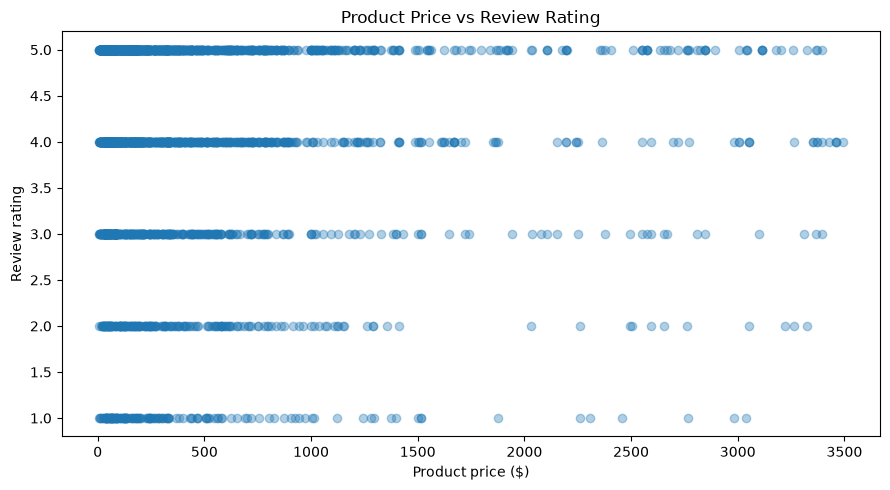

In [2]:

# STEP 2 — PRODUCT PRICE VS REVIEW RATING

product_reviews = reviews.merge(
    products[["id", "price", "category_id"]],
    left_on="product_id",
    right_on="id",
    how="left",
    validate="many_to_one"
)

print("Correlation between product price and review rating:")
print(
    product_reviews[["price", "rating"]]
    .corr()
    .loc["price", "rating"]
    .round(3)
)

plt.figure(figsize=(9, 5))
plt.scatter(
    product_reviews["price"],
    product_reviews["rating"],
    alpha=0.35
)

plt.title("Product Price vs Review Rating")
plt.xlabel("Product price ($)")
plt.ylabel("Review rating")
plt.tight_layout()
plt.show()


### Product Price vs. Review Rating

The Pearson correlation coefficient between product price and review rating was 0.021, indicating a negligible linear relationship between the two variables.

This suggests that higher-priced products did not consistently receive higher ratings in this dataset. However, correlation alone does not establish causation, and a near-zero Pearson coefficient does not rule out possible non-linear relationships.

Correlation between total item quantity and order total:
0.523


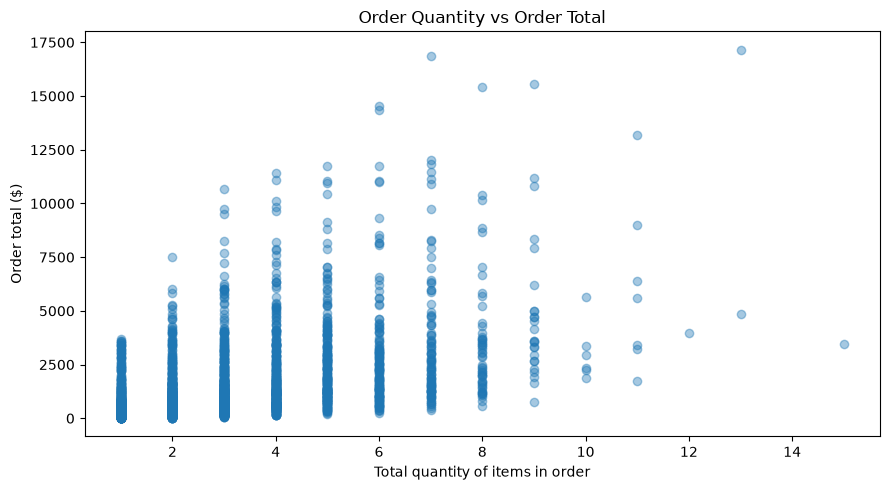

In [3]:

# STEP 3 — ORDER QUANTITY VS ORDER VALUE

order_quantity = (
    order_items.groupby("order_id")
    .agg(
        total_items=("quantity", "sum"),
        item_subtotal=("line_total", "sum")
    )
    .reset_index()
)

order_quantity = order_quantity.merge(
    orders[["id", "total", "status"]],
    left_on="order_id",
    right_on="id",
    how="inner",
    validate="one_to_one"
)

print("Correlation between total item quantity and order total:")
print(
    order_quantity[["total_items", "total"]]
    .corr()
    .loc["total_items", "total"]
    .round(3)
)

plt.figure(figsize=(9, 5))
plt.scatter(
    order_quantity["total_items"],
    order_quantity["total"],
    alpha=0.4
)

plt.title("Order Quantity vs Order Total")
plt.xlabel("Total quantity of items in order")
plt.ylabel("Order total ($)")
plt.tight_layout()
plt.show()


### Order Quantity vs. Order Total

The Pearson correlation coefficient between the total quantity of items in an order and the order total was 0.523, indicating a moderate positive linear relationship.

Orders containing more items tended to have higher total values. However, the relationship was not particularly strong, which may partly reflect differences in product prices. This is a descriptive association and does not establish causation. The analysis includes orders across all statuses, including cancelled and refunded orders.

Correlation between discount and order total:
0.199


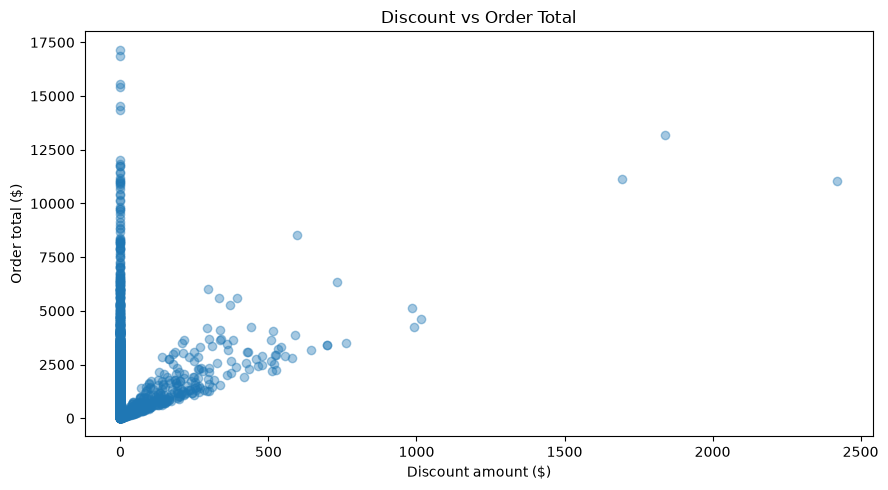

In [4]:

# STEP 4 — DISCOUNT VS ORDER TOTAL

print("Correlation between discount and order total:")
print(
    orders[["discount", "total"]]
    .corr()
    .loc["discount", "total"]
    .round(3)
)

plt.figure(figsize=(9, 5))
plt.scatter(
    orders["discount"],
    orders["total"],
    alpha=0.4
)

plt.title("Discount vs Order Total")
plt.xlabel("Discount amount ($)")
plt.ylabel("Order total ($)")
plt.tight_layout()
plt.show()


### Discount vs. Order Total

The Pearson correlation coefficient between discount amount and order total was 0.199, indicating a weak positive linear relationship.

Orders with larger discounts tended to have slightly higher total values in this dataset. However, this does not mean that discounts caused customers to spend more. Larger orders may receive larger discounts, and the order total is calculated after the discount is applied. Further analysis would be needed to investigate this relationship.

,order_count,median_order_total,mean_order_total,total_order_value,unique_customers
tier,,,,,
gold,468,802.22,1389.04,650068.76,109
platinum,182,798.46,1338.22,243555.14,47
standard,1682,790.03,1411.13,2373517.71,458
silver,668,774.25,1516.68,1013139.00,163


<Figure size 900x500 with 0 Axes>

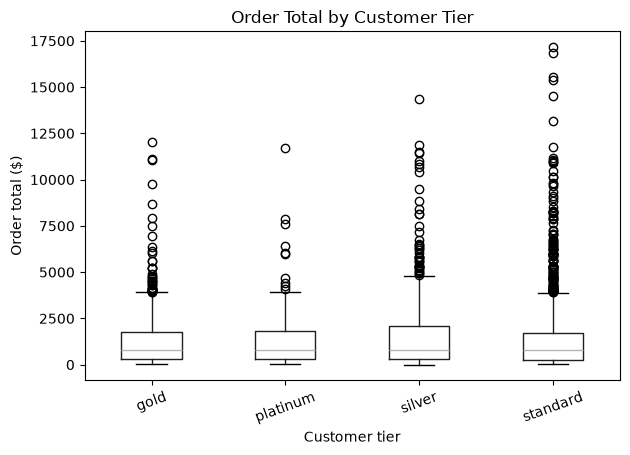

In [5]:

# STEP 5 — CUSTOMER TIER VS ORDER BEHAVIOUR

orders_with_tier = orders.merge(
    customers[["id", "tier"]],
    left_on="customer_id",
    right_on="id",
    how="left",
    validate="many_to_one",
    suffixes=("_order", "_customer")
)

tier_order_summary = (
    orders_with_tier
    .groupby("tier")
    .agg(
        order_count=("id_order", "count"),
        median_order_total=("total", "median"),
        mean_order_total=("total", "mean"),
        total_order_value=("total", "sum"),
        unique_customers=("customer_id", "nunique")
    )
    .sort_values("median_order_total", ascending=False)
    .round(2)
)

display(tier_order_summary)

plt.figure(figsize=(9, 5))
orders_with_tier.boxplot(
    column="total",
    by="tier",
    grid=False
)

plt.title("Order Total by Customer Tier")
plt.suptitle("")
plt.xlabel("Customer tier")
plt.ylabel("Order total ($)")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()


### Customer Tier vs. Order Behaviour

Order values were compared across customer tiers.

- Gold customers had the highest median order total ($802.22).
- Silver customers had the highest mean order total ($1,516.68), potentially reflecting the influence of high-value orders.
- Standard customers accounted for the largest number of orders (1,682), consistent with this tier having the largest customer base.
- Platinum customers had the lowest mean order total ($1,338.22).

The results do not show a consistent increase in order value across customer tiers. These are descriptive comparisons, and differences in group size and the distribution of order values should be considered when interpreting them. Order totals include all recorded statuses, including cancelled and refunded orders.

,order_count,median_total,mean_total,total_order_value
status,,,,
shipped,32,1389.72,2153.89,68924.42
paid,9,950.95,1009.57,9086.16
pending,7,849.77,1202.22,8415.52
cancelled,173,802.63,1590.29,275120.69
delivered,2675,790.20,1419.85,3798097.73
refunded,104,639.18,1159.96,120636.09


<Figure size 1000x500 with 0 Axes>

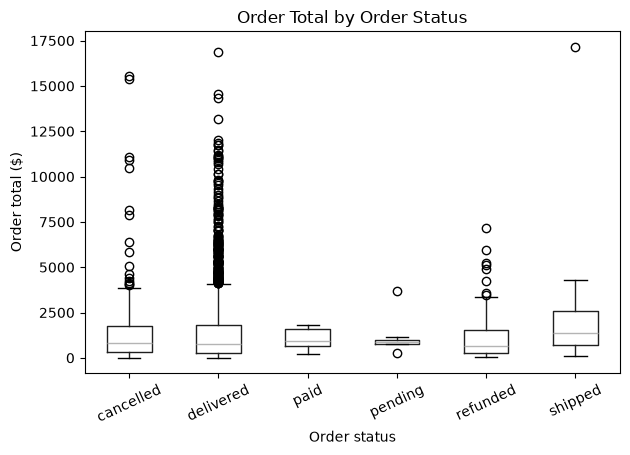

In [6]:

# STEP 6 — ORDER STATUS VS ORDER VALUE

status_order_summary = (
    orders.groupby("status")
    .agg(
        order_count=("id", "count"),
        median_total=("total", "median"),
        mean_total=("total", "mean"),
        total_order_value=("total", "sum")
    )
    .sort_values("median_total", ascending=False)
    .round(2)
)

display(status_order_summary)

plt.figure(figsize=(10, 5))
orders.boxplot(
    column="total",
    by="status",
    grid=False
)

plt.title("Order Total by Order Status")
plt.suptitle("")
plt.xlabel("Order status")
plt.ylabel("Order total ($)")
plt.xticks(rotation=25)
plt.tight_layout()
plt.show()


### Order Status vs. Order Value

Order values were compared across order statuses.

- Shipped orders had the highest median total ($1,389.72), although this group contained only 32 orders.
- Delivered orders accounted for the largest group, with 2,675 orders and a combined recorded order value of $3,798,097.73.
- Cancelled orders had a higher mean total ($1,590.29) than delivered orders ($1,419.85).
- Cancelled orders represented $275,120.69 in recorded order value, while refunded orders represented $120,636.09.

These totals describe recorded order values and should not be interpreted as realized revenue or actual refund amounts. Revenue analysis should account for order status and the available financial fields.

,units_sold,order_item_count,item_sales_value,median_unit_price,unique_products
category_id,,,,,
2,1066,745,1858830.21,1669.41,220
5,1166,803,688252.21,547.65,227
1,996,707,436129.87,432.74,200
4,1058,760,424709.47,377.77,209
8,1147,804,255640.94,216.83,227
3,1204,820,214628.30,175.48,228
7,1003,718,99550.50,99.46,198
6,1223,862,61657.27,53.64,224


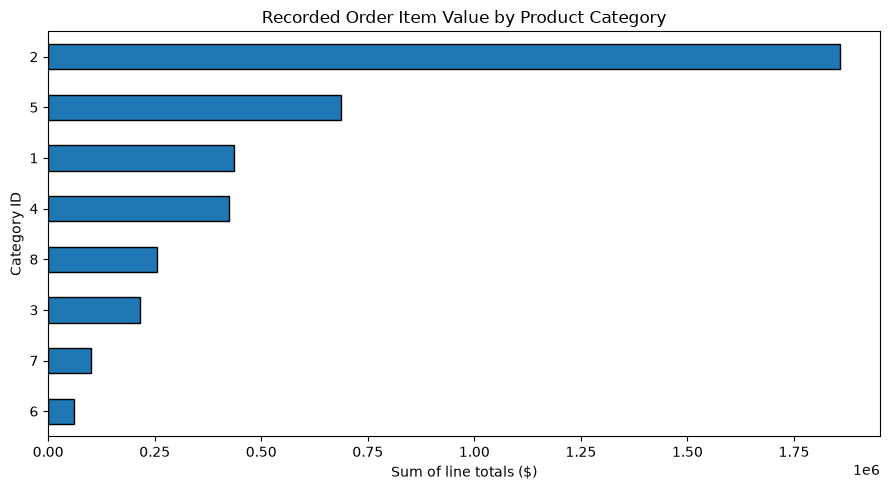

In [7]:

# STEP 7 — PRODUCT CATEGORY SALES ANALYSIS

items_with_category = order_items.merge(
    products[["id", "category_id", "price"]],
    left_on="product_id",
    right_on="id",
    how="left",
    validate="many_to_one",
    suffixes=("_item", "_product")
)

category_sales = (
    items_with_category
    .groupby("category_id")
    .agg(
        units_sold=("quantity", "sum"),
        order_item_count=("order_id", "count"),
        item_sales_value=("line_total", "sum"),
        median_unit_price=("unit_price", "median"),
        unique_products=("product_id", "nunique")
    )
    .sort_values("item_sales_value", ascending=False)
    .round(2)
)

display(category_sales)

plt.figure(figsize=(9, 5))
category_sales["item_sales_value"].sort_values().plot(
    kind="barh",
    edgecolor="black"
)

plt.title("Recorded Order Item Value by Product Category")
plt.xlabel("Sum of line totals ($)")
plt.ylabel("Category ID")
plt.tight_layout()
plt.show()


### Product Category Sales Analysis

Recorded order-item values and quantities were compared across product categories.

- Category 2 generated the highest recorded order-item value ($1,858,830.21) and had the highest median unit price ($1,669.41).
- Category 6 recorded the highest number of units sold (1,223), despite having the lowest total item value ($61,657.27).
- Category 3 also recorded a high unit volume (1,204) but a relatively low item value ($214,628.30).
- Category 5 ranked second in recorded item value, at $688,252.21.

These findings show that sales value and unit volume can produce different category rankings, partly because product prices vary substantially. The figures are sums of order-item line totals across all order statuses, so they should not be interpreted as realized revenue.

,review_count,mean_helpful_votes,median_helpful_votes
rating,,,
1,153,3.96,1.0
2,202,5.49,1.5
3,379,4.70,1.0
4,737,4.60,1.0
5,1029,4.43,0.0



Correlation between rating and helpful votes: -0.011


<Figure size 800x500 with 0 Axes>

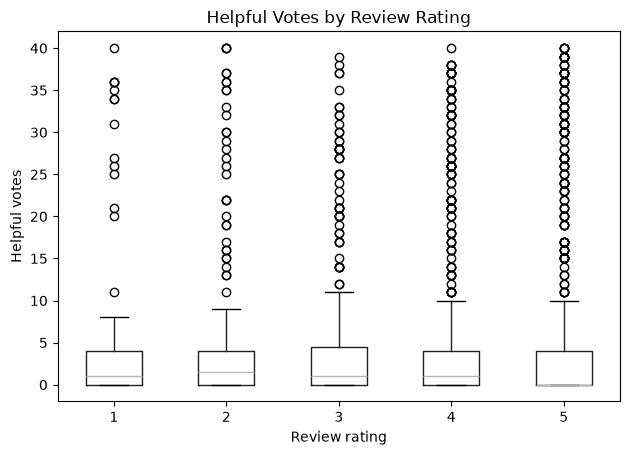

In [8]:

# STEP 8 — REVIEW RATING VS HELPFUL VOTES

review_summary = (
    reviews.groupby("rating")
    .agg(
        review_count=("id", "count"),
        mean_helpful_votes=("helpful_votes", "mean"),
        median_helpful_votes=("helpful_votes", "median")
    )
    .round(2)
)

display(review_summary)

print(
    "\nCorrelation between rating and helpful votes:",
    round(
        reviews[["rating", "helpful_votes"]]
        .corr()
        .loc["rating", "helpful_votes"],
        3
    )
)

plt.figure(figsize=(8, 5))
reviews.boxplot(
    column="helpful_votes",
    by="rating",
    grid=False
)

plt.title("Helpful Votes by Review Rating")
plt.suptitle("")
plt.xlabel("Review rating")
plt.ylabel("Helpful votes")
plt.tight_layout()
plt.show()


### Review Rating vs. Helpful Votes

Helpful votes were compared across review rating groups.

- Two-star reviews had the highest mean helpful-vote count (5.49).
- Five-star reviews had the lowest median helpful-vote count (0), despite being the largest rating group.
- Mean helpful-vote counts exceeded median values across all rating groups, suggesting that a smaller number of reviews with high vote counts may influence the averages.

These descriptive results do not establish whether review ratings are associated with helpfulness. The correlation coefficient and further analysis would be needed to assess the relationship more directly.

# Key Findings — Bivariate and Multivariate EDA

## Main Findings

- **Product price and review rating:** The Pearson correlation was 0.021, indicating a negligible linear relationship.
- **Order quantity and order total:** The correlation was 0.523, indicating a moderate positive linear relationship.
- **Discount and order total:** The correlation was 0.199, indicating a weak positive linear relationship.
- **Customer tier and order behaviour:** Order values did not increase consistently across customer tiers. Gold customers had the highest median order total, while silver customers had the highest mean.
- **Order status and value:** Delivered orders accounted for most recorded orders. Cancelled and refunded orders also had substantial recorded values.
- **Product category performance:** Category 2 had the highest recorded order-item value, whereas Category 6 had the highest unit volume.
- **Review ratings and helpfulness:** Two-star reviews had the highest mean helpful-vote count, while five-star reviews had a median of zero.

## Limitations

These findings describe associations rather than causal relationships. Pearson correlation captures linear relationships and may not identify non-linear patterns. Group sizes and outliers can influence summary statistics.

Order totals and item values include orders across different statuses, including cancelled and refunded orders. Therefore, these values should not automatically be interpreted as realized revenue. Customer-tier labels also cannot be assumed to represent spending levels without confirming how tiers are defined.

Further relational analysis and statistical testing will help investigate these patterns more rigorously.